In [ ]:
car_evaluation.csv

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

In [3]:
df = pd.read_csv("car_evaluation.csv", header=None)

df.columns = [
    "buying", "maint", "doors",
    "persons", "lug_boot", "safety", "class"
]

print(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Dataset shape: (1728, 7)

Missing values:
 buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


In [4]:
X = df.drop("class", axis=1)
y = df["class"]

print("Input features:", X.columns.tolist())
print("\nTarget classes:\n", y.value_counts())

Input features: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']

Target classes:
 class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1382
Testing samples: 346


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"), X.columns)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 97.98 %


In [9]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Report:

              precision    recall  f1-score   support

         acc       0.94      0.97      0.96        77
        good       1.00      0.93      0.96        14
       unacc       0.99      0.99      0.99       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.98      0.95      0.97       346
weighted avg       0.98      0.98      0.98       346



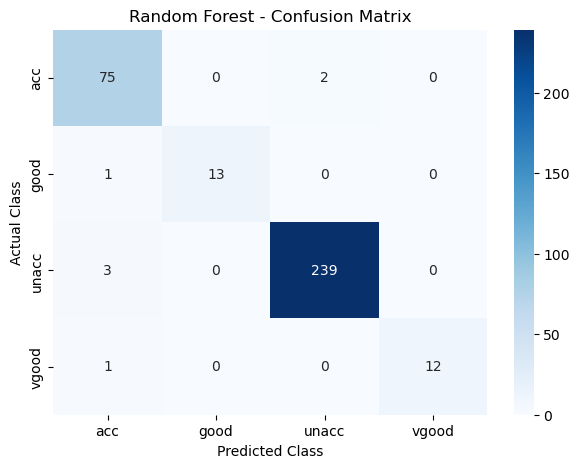

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [11]:
sample_car = pd.DataFrame([{
    "buying": "low",
    "maint": "low",
    "doors": "4",
    "persons": "4",
    "lug_boot": "big",
    "safety": "high"
}])

prediction = model.predict(sample_car)

print("Predicted car acceptability:", prediction[0])

Predicted car acceptability: vgood


                    Feature  Importance
12       encoder__persons_2    0.099214
18     encoder__safety_high    0.092312
19      encoder__safety_low    0.087529
17  encoder__lug_boot_small    0.071173
20      encoder__safety_med    0.064665
7      encoder__maint_vhigh    0.053998
1       encoder__buying_low    0.053609
15    encoder__lug_boot_big    0.052836
0      encoder__buying_high    0.052165
3     encoder__buying_vhigh    0.050885


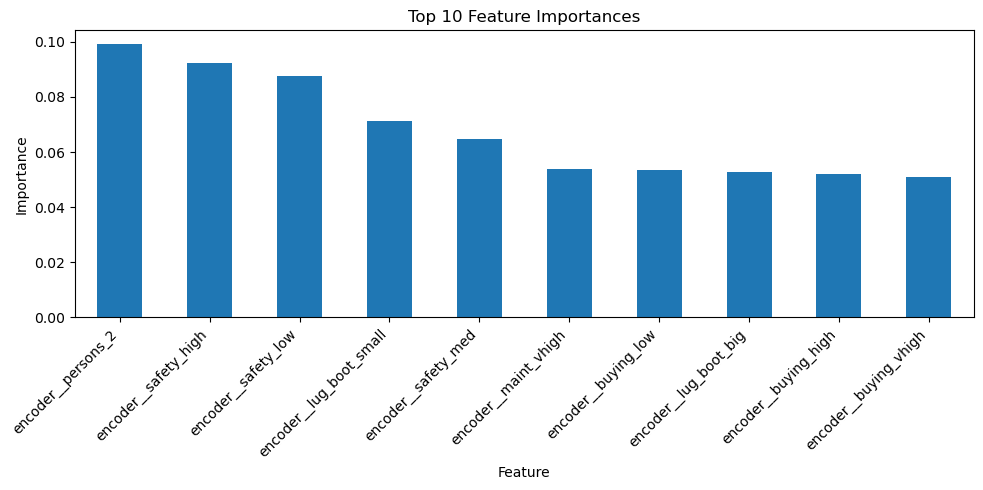

In [12]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print(importance_df.head(10))

importance_df.head(10).plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Top 10 Feature Importances")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()